# 06 - Comparison-sentence application

This presentation-only notebook reads the artifacts produced by `python -m yelptext app comparisons --config configs/sample.toml`. The application scans the shared 50,000-review sample and detects sentences that compare the reviewed business with other businesses or prior business experiences.

In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import pandas as pd

def find_root():
    start = Path.cwd().resolve()
    for candidate in (start, *start.parents):
        if (candidate / 'pyproject.toml').is_file():
            return candidate
    raise RuntimeError('Run this notebook inside the project repository')

ROOT = find_root()
RESULT_DIR = ROOT / 'artifacts' / 'application' / 'comparisons'
summary = json.loads((RESULT_DIR / 'comparison_summary.json').read_text(encoding='utf-8'))
matches = pd.read_csv(RESULT_DIR / 'comparison_sentences.csv')
assert summary['status'] == 'COMPLETED'
print(f"Displaying: {RESULT_DIR.relative_to(ROOT)}")

Displaying: artifacts\application\comparisons


In [2]:
pd.DataFrame([{
    'reviews scanned': summary['reviews_scanned'],
    'sentences scanned': summary['sentences_scanned'],
    'matched reviews': summary['matched_reviews'],
    'matched sentences': summary['matched_sentences'],
    'review match rate': summary['matched_reviews'] / summary['reviews_scanned'],
}]).style.format({'review match rate': '{:.2%}'})

,reviews scanned,sentences scanned,matched reviews,matched sentences,review match rate
0,50000,396907,3164,3342,6.33%


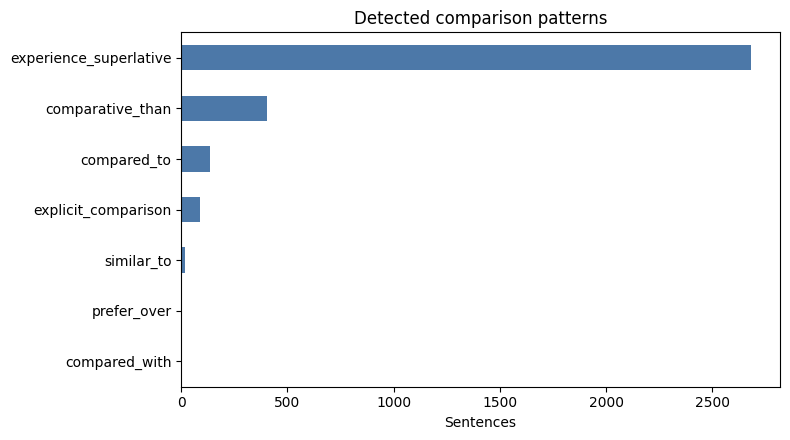

In [3]:
pattern_counts = matches['pattern'].value_counts().sort_values()
axis = pattern_counts.plot.barh(figsize=(8, 4.5), color='#4C78A8')
axis.set_title('Detected comparison patterns')
axis.set_xlabel('Sentences')
axis.set_ylabel('')
plt.tight_layout()
plt.show()

## Representative detections

The table shows up to three sentences per rule so that the application can be inspected qualitatively rather than evaluated only by its match count.

In [4]:
examples = (
    matches.sort_values(['pattern', 'doc_id', 'sentence_index'])
    .groupby('pattern', sort=True)
    .head(3)
)
examples[['pattern', 'business_name', 'stars', 'sentence']]

,pattern,business_name,stars,sentence
2700,comparative_than,Ragazzi Northern Italian Restaurant,2.0,"I encourage the chef to visit Italy, it is sad..."
2736,comparative_than,Napoli Pizza & Pasta,5.0,And their chicken cheesesteak is better than o...
1060,comparative_than,Idaho Pizza Company,4.0,They don't offer the buffet and the pizzas run...
692,compared_to,Vapor Bay,5.0,"The caliber of their juice here, compared to a..."
1190,compared_to,The Habit Burger Grill,5.0,I can't wait untill they open to try some of t...
3209,compared_to,Lavender Nail & Spa,5.0,I have gotten the facial a handful of times an...
705,compared_with,Tequilas Restaurant,4.0,The seafood was particularly good here compare...
1653,compared_with,Roly Poly,4.0,"The owner and staff are friendly, the quality ..."
2522,compared_with,Mellow Mushroom - Brandon,1.0,"It is always very sparse with the toppings, co..."
157,experience_superlative,Philly Dat Up,1.0,Worst place ever!!!


## Interpretation and limitations

The detector is deliberately lightweight and explainable. It uses the project tokenizer plus explicit comparison templates and business-reference words; it does not perform named-entity recognition or resolve every implicit comparison. Consequently, the output is a mined candidate set rather than a gold-standard classification. The rule labels make both useful detections and remaining false positives easy to inspect.